In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def get_total_size_mb(folder_path):
    total_size = 0
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.m4s', '.webm')):
                file_path = os.path.join(root, file)
                total_size += os.path.getsize(file_path)
    return total_size / (1024 * 1024)  # bytes -> MB

folder = "./output_v3/cat00_v2_ccrf/FULL_h264/"
print(f"Total size: {get_total_size_mb(folder):.2f} MB")

Total size: 117.94 MB


## What is happening with Lost Lace, Consort Radahn and Radagon?

In [3]:
def build_transcoding_df(path):
    codec_list = ['h264','vp9','av1']
    encodings = ['ccrf', 'cbr', 'cvbr']
    transcoding_energy = pd.DataFrame()
    for vid_enc in os.listdir(path):
    
        [vid,enc] = vid_enc.split("_")[0],vid_enc.split("_")[2]
        for f in os.listdir(f"{path}/{vid_enc}/"):
            codec = f.split("_")[1]
            definition = f.split("_")[0]
            if codec in codec_list:  
                df = pd.read_csv(f"{path}/{vid_enc}/{f}/energy.csv")
                df['total_power'] = (df['rapl0_delta_uj'] + df['rapl1_delta_uj']) * (1e-6)
                size = get_total_size_mb(f"{path}/{vid_enc}/{f}/")
                if enc=="cbr":
                    l,u=10,10
                else:
                    l,u = 10,10
                    
                time = len(df[l:-u])
                # print(time)
                energy = df[l:-u]['total_power'].sum()
                power = df[l:-u]['total_power'].mean()
    
                transcoding_energy = pd.concat([transcoding_energy,pd.DataFrame({
                    "vid":[vid],
                    "enc":[enc],
                    "codec":[codec],
                    "energy":[energy],
                    "time":[time],
                    "power":[power],
                    "size":[size],
                    "definition":[definition]
                })])
        
    transcoding_energy = transcoding_energy.reset_index(drop=True)        
    
    # transcoding_energy_ccrf = transcoding_energy[transcoding_energy['enc']=='ccrf'].copy()
    
    # transcoding_energy_ccrf = transcoding_energy_ccrf.groupby(['vid']).agg({
    #     'energy':'sum',
    #     'time':'max',
    #     'power':'mean',
    #     'size':'sum'
    # })
    # transcoding_energy_ccrf =transcoding_energy_ccrf.reset_index()
    return transcoding_energy


In [4]:
v4 = build_transcoding_df("./output_v4/")

In [11]:
v4.to_csv("./complete_transcoding_energy_v4.csv",index=False)

In [6]:
transcoding_energy = v4

In [7]:
transcoding_energy = transcoding_energy[~((transcoding_energy['codec'] == 'h264') & (transcoding_energy['definition'] == 'QUHD'))].copy()

<Axes: xlabel='definition', ylabel='power'>

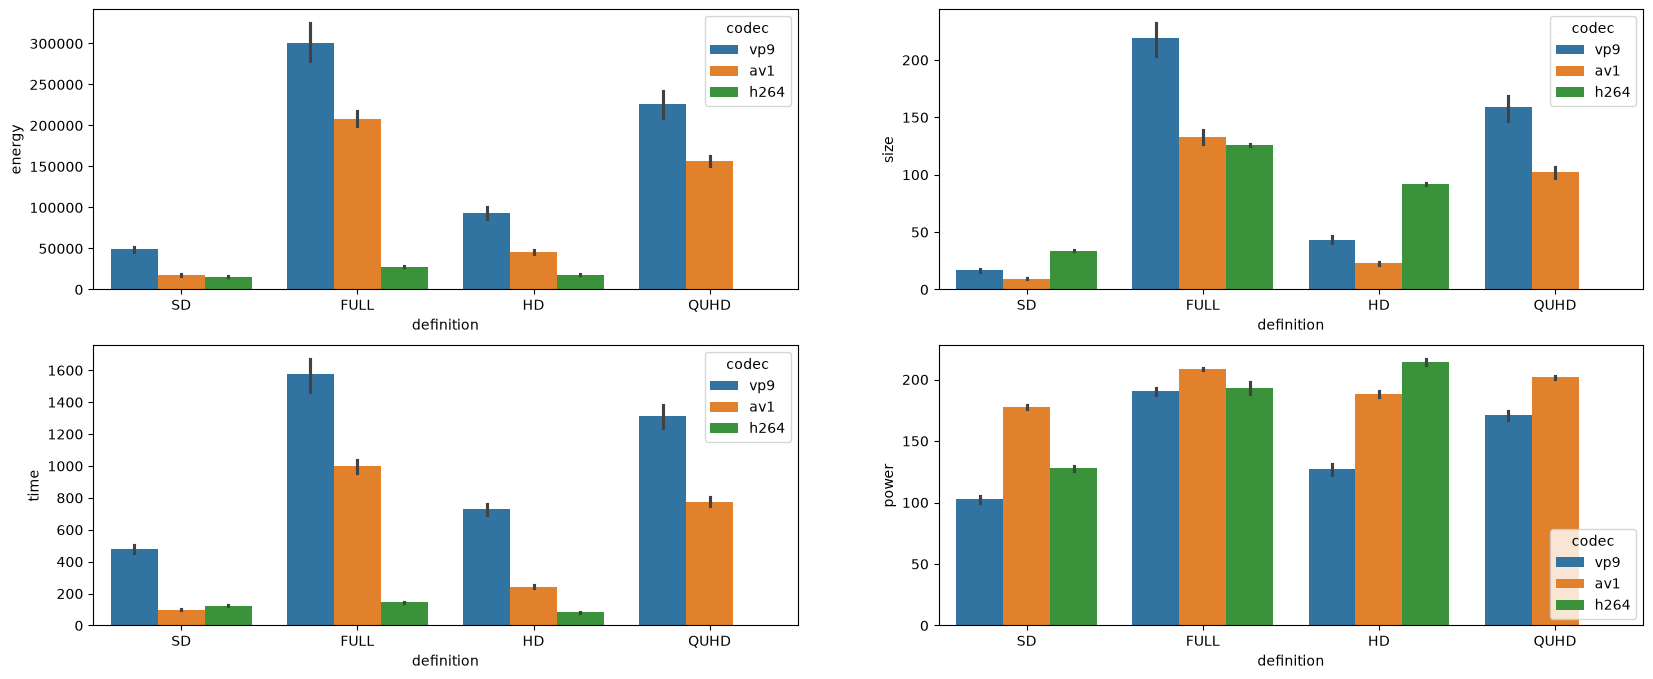

In [8]:
fig,axes = plt.subplots(2,2,figsize=(20,8))
axes = axes.flatten()
sns.barplot(data = transcoding_energy, x='definition', y='energy',hue='codec',ax = axes[0])
sns.barplot(data = transcoding_energy, x='definition', y='size',hue='codec',ax = axes[1])
sns.barplot(data = transcoding_energy, x='definition', y='time',hue='codec',ax = axes[2])
sns.barplot(data = transcoding_energy, x='definition', y='power',hue='codec',ax = axes[3])

In [12]:
transcoding_energy_full = transcoding_energy[transcoding_energy['definition']=='FULL'].copy()
transcoding_energy_full.to_csv("./full_transcoding_energy_v4.csv",index=False)

transcoding_energy_split = transcoding_energy[transcoding_energy['definition']!='FULL'].copy()
transcoding_energy_split.to_csv("./split_transcoding_energy_v4.csv",index=False)

In [10]:
transcoding_energy_full

,vid,enc,codec,energy,time,power,size,definition
1,cat02,ccrf,vp9,277311.968486,1450,191.249633,255.698228,FULL
2,cat02,ccrf,av1,192356.898801,933,206.170310,127.494249,FULL
5,cat02,ccrf,h264,27390.102245,150,182.600682,126.654421,FULL
12,cat09,ccrf,vp9,312398.541260,1639,190.603137,201.209399,FULL
13,cat09,ccrf,av1,216865.024720,1032,210.140528,137.486514,FULL
16,cat09,ccrf,h264,28838.720972,144,200.268896,126.615390,FULL
23,cat03,ccrf,vp9,293506.614526,1529,191.959853,243.581735,FULL
24,cat03,ccrf,av1,198861.998115,959,207.363919,133.243134,FULL
27,cat03,ccrf,h264,27404.086950,142,192.986528,126.601371,FULL
34,cat05,ccrf,vp9,296370.745622,1558,190.225126,208.788414,FULL


In [11]:
transcoding_energy_split_agg = transcoding_energy_split.groupby(['vid','codec']).agg({
    'energy':'sum',
    'time':'max',
    'power':'sum',
    'size':'sum'
}).reset_index()

In [18]:
transcoding_energy_full[transcoding_energy_full['vid']=='cat15']

,vid,enc,codec,energy,time,power,size,definition
85,cat15,ccrf,vp9,94370.852893,543,173.795309,118.020029,FULL
86,cat15,ccrf,av1,23339.218754,114,204.729989,92.905694,FULL
90,cat15,ccrf,h264,24576.952952,177,138.852842,126.164613,FULL


In [16]:
transcoding_energy_split_agg[transcoding_energy_split_agg['vid']=='cat15']

,vid,codec,energy,time,power,size
33,cat15,av1,29499.926493,55,602.799837,135.485605
34,cat15,h264,26510.063054,126,343.605406,126.145121
35,cat15,vp9,147337.038830,667,316.768931,118.020029


## AI Inference

In [42]:
def plot_inference_power(model):
    cpu = pd.read_csv(f"../inferenceEnergy/cpu_energy_{model}.csv")
    cpu['total_power'] = (cpu['rapl0_delta_uj'] + cpu['rapl1_delta_uj']) * (1e-6)
    gpu = pd.read_csv(f"../inferenceEnergy/gpu_energy_{model}.csv")
    cpu_energy = cpu[30:-30]['total_power'].sum()
    gpu_energy = gpu[30:-30][' power.draw [W]'].sum()
    
    cpu_time = len(cpu[30:-30])
    gpu_time = len(gpu[30:-30])
    
    fig,axes = plt.subplots(1,2,figsize=(15,5))
    
    sns.lineplot(data = cpu, y ='total_power', x = cpu.index, ax = axes[0])
    axes[0].set_title(f"CPU Energy:{cpu_energy:.2f} J")
    sns.lineplot(data = gpu, y =' power.draw [W]', x = gpu.index, ax = axes[1])
    axes[1].set_title(f"GPU Energy:{gpu_energy:.2f} J")

In [9]:
500 * 60 * 24

720000

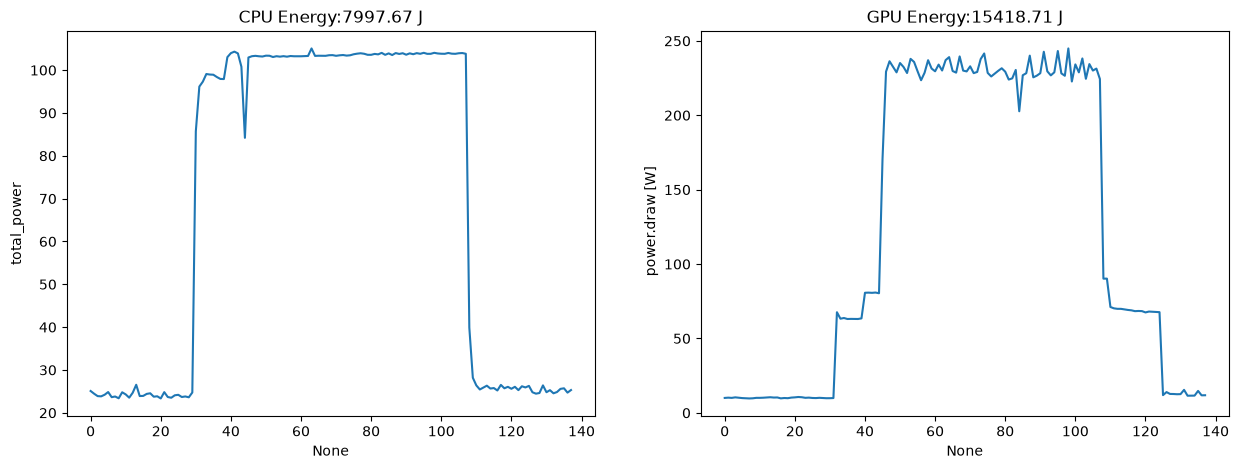

In [43]:
plot_inference_power("gemma4")

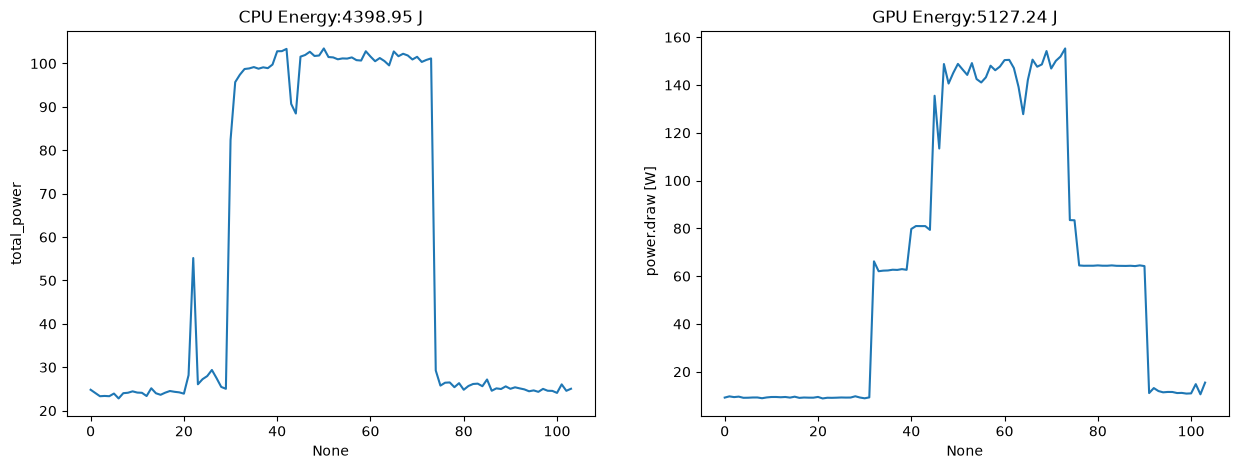

In [44]:
plot_inference_power("qwen36")